# Block 2 Checkpoint - Four-Body Collision Demo

**Student:** Zaki Daouk  
**Date:** 2026-10-18

Four circular bodies move under gravity and quadratic drag, with elastic body-body collisions enabled through the engine's optional collision handler. The two force types are registered with the world; the notebook contains no simulation time-stepping loop. The panels show trajectories relative to the center of mass, mechanical-energy decay from drag, momentum change from external forces, and per-collision conservation diagnostics.

Run all cells from top to bottom. The final cell saves a multi-panel presentation figure to `checkpoints/block2_checkpoint_results.png`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from project_paths import add_to_path, project_root

engine_dir = add_to_path(
    "lab07_engine",
    subdirs=("", "src", "labs/lab07", "lab07", "phys311/labs/lab07"),
)
repo_root = project_root(markers=(".git",), start=engine_dir)

from lab07_engine import (
    Body,
    Drag,
    ElasticCircleCollisions,
    EulerCromer,
    Gravity,
    World,
)

checkpoint_dir = repo_root / "checkpoints"
checkpoint_dir.mkdir(exist_ok=True)

## Scene setup and engine run

The four equal-mass disks start in a row. The left disk moves right and the right disk moves left, initiating a sequence of elastic collisions. Gravity and quadratic drag act continuously. Drag removes mechanical energy; gravity and drag are external to the four-disk system, so its total momentum is not expected to remain constant. Each isolated elastic collision should conserve the colliding pair's momentum and kinetic energy.

In [2]:
body_mass = 1.0
body_radius = 0.5
gravity_strength = 2.0
drag_coefficient = 0.015
time_step = 0.001
duration = 6.0
step_count = int(duration / time_step)

collision_handler = ElasticCircleCollisions(restitution=1.0)
world = World(EulerCromer(), collision_handler=collision_handler)
initial_x = (-3.0, -1.0, 1.0, 3.0)
initial_vx = (2.0, 0.0, 0.0, -1.0)
for x, vx in zip(initial_x, initial_vx):
    world.add_body(
        Body(body_mass, [x, 0.0], [vx, 0.0], radius=body_radius)
    )

world.add_force(Gravity(gravity_strength))
world.add_force(Drag(drag_coefficient))
world.run(steps=step_count, dt=time_step)

times = np.array([state.time for state in world.history])
positions = np.array([state.positions for state in world.history])
kinetic_energy = np.array([state.kinetic_energy for state in world.history])
potential_energy = np.array([state.potential_energy for state in world.history])
mechanical_energy = np.array([state.total_energy for state in world.history])
momentum = np.array([state.momentum for state in world.history])
center_of_mass = np.mean(positions, axis=1)
relative_positions = positions - center_of_mass[:, np.newaxis, :]

collision_events = collision_handler.events
collision_momentum_errors = np.array([
    np.linalg.norm(np.subtract(event.momentum_after, event.momentum_before))
    for event in collision_events
])
collision_energy_errors = np.array([
    abs(event.kinetic_energy_after - event.kinetic_energy_before)
    for event in collision_events
])
collision_restitution = np.array([
    -event.normal_speed_after / event.normal_speed_before
    for event in collision_events
])

assert len(world.bodies) == 4
assert len(world.forces) == 2
assert len(collision_events) >= 1
assert mechanical_energy[-1] < mechanical_energy[0]
assert np.max(collision_momentum_errors) < 1e-12
assert np.max(collision_energy_errors) < 1e-12
assert np.allclose(collision_restitution, 1.0, rtol=1e-12, atol=1e-12)

## Multi-panel validation figure

The first three panels show the scene and system-level diagnostics. The collision panel directly checks each event: restitution should be 1, and the pair's momentum and kinetic-energy errors should be near floating-point roundoff. Between collisions the external drag changes mechanical energy, while gravity/drag also change the four-body momentum.

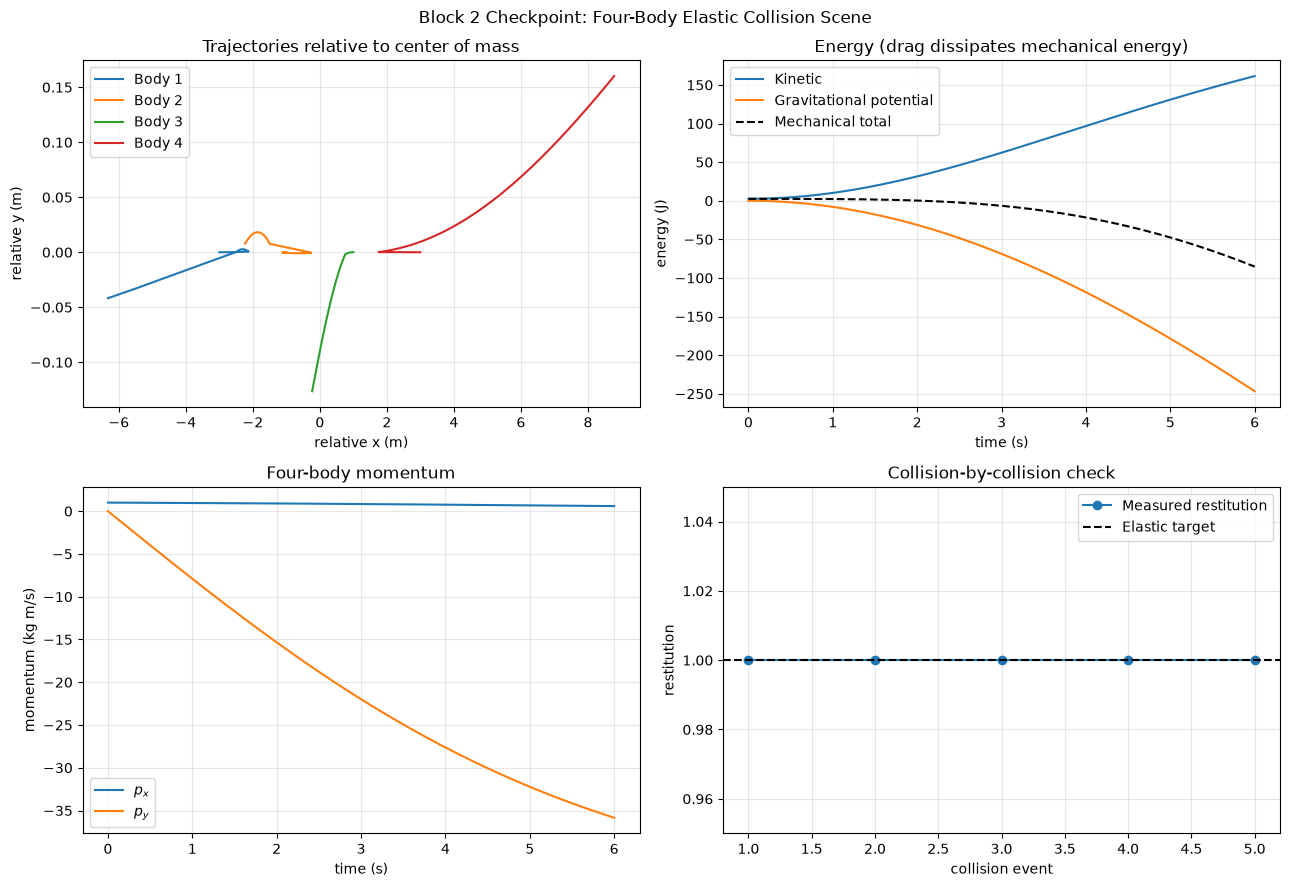

Bodies: 4; force types: Gravity and Drag
Elastic collision events: 5
Mechanical energy: 2.500 J -> -85.331 J (decreases due to drag)
Maximum pair momentum error at impact: 1.110e-16 kg m/s
Maximum pair kinetic-energy error at impact: 1.776e-15 J
Measured collision restitution range: 1.000000000000 to 1.000000000000
Saved presentation figure: C:\Users\zakid\OneDrive\EDU\python\phys311\checkpoints\block2_checkpoint_results.png


In [3]:
figure, axes = plt.subplots(2, 2, figsize=(13, 9))

for body_index in range(len(world.bodies)):
    axes[0, 0].plot(
        relative_positions[:, body_index, 0],
        relative_positions[:, body_index, 1],
        label=f"Body {body_index + 1}",
    )
axes[0, 0].set(
    title="Trajectories relative to center of mass",
    xlabel="relative x (m)",
    ylabel="relative y (m)",
)
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(times, kinetic_energy, label="Kinetic")
axes[0, 1].plot(times, potential_energy, label="Gravitational potential")
axes[0, 1].plot(times, mechanical_energy, "k--", label="Mechanical total")
axes[0, 1].set(title="Energy (drag dissipates mechanical energy)", xlabel="time (s)", ylabel="energy (J)")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(times, momentum[:, 0], label="$p_x$")
axes[1, 0].plot(times, momentum[:, 1], label="$p_y$")
axes[1, 0].set(title="Four-body momentum", xlabel="time (s)", ylabel="momentum (kg m/s)")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

event_numbers = np.arange(1, len(collision_events) + 1)
axes[1, 1].plot(event_numbers, collision_restitution, "o-", label="Measured restitution")
axes[1, 1].axhline(1.0, color="black", linestyle="--", label="Elastic target")
axes[1, 1].set(title="Collision-by-collision check", xlabel="collision event", ylabel="restitution")
axes[1, 1].set_ylim(0.95, 1.05)
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)
figure.suptitle("Block 2 Checkpoint: Four-Body Elastic Collision Scene")
figure.tight_layout()

results_path = checkpoint_dir / "block2_checkpoint_results.png"
figure.savefig(results_path, dpi=160, bbox_inches="tight")
plt.show()

print(f"Bodies: {len(world.bodies)}; force types: Gravity and Drag")
print(f"Elastic collision events: {len(collision_events)}")
print(f"Mechanical energy: {mechanical_energy[0]:.3f} J -> {mechanical_energy[-1]:.3f} J (decreases due to drag)")
print(f"Maximum pair momentum error at impact: {np.max(collision_momentum_errors):.3e} kg m/s")
print(f"Maximum pair kinetic-energy error at impact: {np.max(collision_energy_errors):.3e} J")
print(f"Measured collision restitution range: {collision_restitution.min():.12f} to {collision_restitution.max():.12f}")
print(f"Saved presentation figure: {results_path}")